**Notebook 05: Prices and savings potential for dapagliflozin**

This notebook answers RQ4. It uses the EPD extract from notebook 05a to look at the price of generic dapagliflozin from September 2025 (the first full month of generic supply) and to estimate three savings figures for the 465 practices in the three ICBs.

Savings 1 (realised) is what the fall in the generic price has already saved. Savings 2 (like-for-like) is what would be saved if all branded Forxiga items were prescribed as generic dapagliflozin. Savings 3 (national median) is what would be saved if every practice below the national median generic share moved up to that median.

Inputs: `epd_sglt2_extract.csv`, `practice_master_lookup.csv`, `op_wm_cleaned.csv` and `dapagliflozin_measure_sicbl.csv`.

Outputs: `monthly_savings.csv`, `district_savings.csv`, `icb_savings.csv`, `savings_summary.csv`, `dapagliflozin_price_per_tablet.png` and `epd_savings_analysis.png`.

All costs are Net Ingredient Cost (NIC), which is the list price before discounts.

**Step 1: Load libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

POST_START = '2025-09-01'   # first full month of generic supply

print('Libraries loaded')

Libraries loaded


**Step 2: Load the EPD extract and keep the 465 practices**

The extract also holds some practices in the three ICBs that are not in the 2024/25 practice list. They are left out so the savings match the regression sample. The table shows how little prescribing this removes.

In [2]:
epd = pd.read_csv('epd_sglt2_extract.csv', dtype={'PRACTICE_CODE': str, 'ICB_CODE': str},
                  parse_dates=['date'])
master = pd.read_csv('practice_master_lookup.csv')

epd['in_master'] = epd['PRACTICE_CODE'].isin(master['PRACTICE_CODE'])
outside = epd[~epd['in_master']]
print('Rows in extract:', len(epd), '| months:', epd['date'].nunique())
print('Practices outside the master list:', outside['PRACTICE_CODE'].nunique(),
      '| their share of items:', round(outside['ITEMS'].sum() / epd['ITEMS'].sum() * 100, 2), '%')

x = epd[epd['in_master']].merge(
    master[['PRACTICE_CODE', 'icb', 'district', 'SUB_ICB_ODS_CODE']],
    on='PRACTICE_CODE', how='left')
print('Practices used:', x['PRACTICE_CODE'].nunique())

Rows in extract: 128267 | months: 18
Practices outside the master list: 85 | their share of items: 0.2 %
Practices used: 465


**Step 3: Group the items into three categories**

Generic dapagliflozin means the single-agent chemical Dapagliflozin that is not Forxiga. Forxiga is the branded product. Everything else is another SGLT2 product, such as empagliflozin, canagliflozin and the combination tablets. Strength (5 mg or 10 mg) is pulled from the product name because the price differs slightly by strength.

In [3]:
is_dapa = x['BNF_CHEMICAL_SUBSTANCE'].eq('Dapagliflozin')
is_forxiga = x['BNF_PRESENTATION_NAME'].str.startswith('Forxiga')

x['category'] = np.select([is_dapa & ~is_forxiga, is_dapa & is_forxiga],
                          ['Generic dapagliflozin', 'Forxiga (branded)'],
                          default='Other SGLT2')
x['strength'] = x['BNF_PRESENTATION_NAME'].str.extract(r'(\d+)\s*mg')[0]
x['gen_items'] = np.where(x['category'] == 'Generic dapagliflozin', x['ITEMS'], 0)
x['post'] = x['date'] >= POST_START

print(x.groupby(['category', 'BNF_PRESENTATION_NAME'])[['ITEMS', 'TOTAL_QUANTITY', 'NIC']]
      .sum().round(0).head(12).to_string())
print()
print(x.groupby('category')['ITEMS'].sum().to_string())

                                                                     ITEMS  TOTAL_QUANTITY         NIC
category              BNF_PRESENTATION_NAME                                                           
Forxiga (branded)     Forxiga 10mg tablets                            7675        259336.0    338898.0
                      Forxiga 5mg tablets                              344          9596.0     12540.0
Generic dapagliflozin Dapagliflozin 10mg tablets                    956367      30771954.0  22489733.0
                      Dapagliflozin 5mg tablets                      39459       1316231.0    997988.0
Other SGLT2           Canagliflozin 100mg tablets                    30026       1063010.0   1389020.0
                      Canagliflozin 300mg tablets                    35301       1194030.0   1560227.0
                      Canagliflozin 50mg / Metformin 1g tablets        986         65354.0     42699.0
                      Canagliflozin 50mg / Metformin 850mg tablets     24

**Step 4: Check the extract against OpenPrescribing**

If the extract and the cleaned classification are right, the generic share worked out from the EPD should match the OpenPrescribing share used in notebooks 02 to 04. Differences are shown for the three ICBs in each of the 18 months.

In [4]:
epd_share = (x.groupby(['SUB_ICB_ODS_CODE', 'date'])
               .agg(gen=('gen_items', 'sum'), total=('ITEMS', 'sum')).reset_index())
epd_share['epd_share'] = epd_share['gen'] / epd_share['total']

op_wm = pd.read_csv('op_wm_cleaned.csv', parse_dates=['date'])
op_wm['op_share'] = (op_wm['denominator'] - op_wm['numerator']) / op_wm['denominator']

check = epd_share.merge(op_wm[['org_id', 'date', 'op_share']],
                        left_on=['SUB_ICB_ODS_CODE', 'date'], right_on=['org_id', 'date'])
check['abs_diff'] = (check['epd_share'] - check['op_share']).abs()

print('ICB-months compared:', len(check))
print('Mean absolute difference in share:', round(check['abs_diff'].mean(), 4))
print('Largest absolute difference in share:', round(check['abs_diff'].max(), 4))

ICB-months compared: 54
Mean absolute difference in share: 0.0001
Largest absolute difference in share: 0.0036


**Step 5: Price per tablet over time**

This is the key table for the savings. Before September 2025, tablets prescribed as generic dapagliflozin were reimbursed at the same price as Forxiga, so there was nothing to save. From September 2025, the generic price falls month by month. The Forxiga price stays flat.

In [5]:
prices = (x[x['category'] != 'Other SGLT2']
          .groupby(['date', 'category', 'strength'])
          .agg(items=('ITEMS', 'sum'), quantity=('TOTAL_QUANTITY', 'sum'),
               nic=('NIC', 'sum')).reset_index())
prices['price_per_tablet'] = prices['nic'] / prices['quantity']

price_table = prices.pivot_table(index='date', columns=['category', 'strength'],
                                 values='price_per_tablet')
print(price_table.round(3).to_string())

cost_item = (x.assign(group=np.where(x['category'] == 'Generic dapagliflozin',
                                     'Generic dapagliflozin', 'All other SGLT2 items'))
             .groupby(['date', 'group']).agg(items=('ITEMS', 'sum'), nic=('NIC', 'sum')).reset_index())
cost_item['cost_per_item'] = cost_item['nic'] / cost_item['items']
cost_item_table = cost_item.pivot(index='date', columns='group', values='cost_per_item')
print('\nAverage cost per item (GBP):')
print(cost_item_table.round(2).to_string())

category   Forxiga (branded)        Generic dapagliflozin       
strength                  10      5                    10      5
date                                                            
2025-01-01             1.307  1.307                 1.307  1.307
2025-02-01             1.307  1.307                 1.307  1.307
2025-03-01             1.307  1.307                 1.307  1.307
2025-04-01             1.307  1.307                 1.307  1.307
2025-05-01             1.307  1.307                 1.307  1.307
2025-06-01             1.307  1.307                 1.307  1.307
2025-07-01             1.307  1.307                 1.307  1.307
2025-08-01             1.307  1.307                 1.307  1.307
2025-09-01             1.307  1.307                 1.077  0.925
2025-10-01             1.307  1.307                 0.497  0.537
2025-11-01             1.307  1.307                 0.497  0.537
2025-12-01             1.307  1.307                 0.324  0.344
2026-01-01             1.

**Step 6: Chart of the generic price**

The chart shows the price per 10 mg tablet for generic dapagliflozin and Forxiga, with September 2025 marked. It is saved as `dapagliflozin_price_per_tablet.png`.

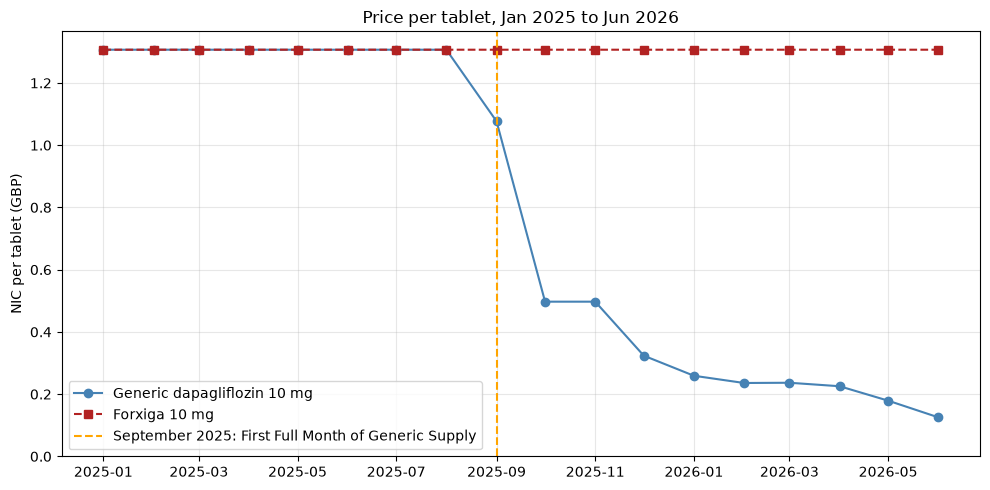

In [6]:
gen10 = prices[(prices['category'] == 'Generic dapagliflozin') & (prices['strength'] == '10')]
fx10 = prices[(prices['category'] == 'Forxiga (branded)') & (prices['strength'] == '10')]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(gen10['date'], gen10['price_per_tablet'], 'o-', color='steelblue',
        label='Generic dapagliflozin 10 mg')
ax.plot(fx10['date'], fx10['price_per_tablet'], 's--', color='firebrick',
        label='Forxiga 10 mg')
ax.axvline(pd.Timestamp(POST_START), color='orange', linestyle='--',
           label='September 2025: First Full Month of Generic Supply')
ax.set_ylabel('NIC per tablet (GBP)')
ax.set_title('Price per tablet, Jan 2025 to Jun 2026')
ax.set_ylim(0, None)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig('dapagliflozin_price_per_tablet.png', dpi=300, bbox_inches='tight')
plt.show()

**Step 7: Savings 1 and 2 (realised and like-for-like)**

Savings 1 compares what generic dapagliflozin tablets actually cost from September 2025 with what they would have cost at the old price. The old price is the average price per tablet from Jan to Aug 2025, worked out by strength. This saving comes from the fall in the national generic price, not from changes in practice behaviour.

Savings 2 takes each Forxiga tablet prescribed from September 2025 and compares its cost with the generic price per tablet in the same month and of the same strength. Only September 2025 onwards is counted.

In [7]:
# Savings 1: realised
pre = prices[(prices['category'] == 'Generic dapagliflozin') & (prices['date'] < POST_START)]
pre_sum = pre.groupby('strength')[['nic', 'quantity']].sum()
ref_price = pre_sum['nic'] / pre_sum['quantity']
print('Reference price per tablet (Jan to Aug 2025):')
print(ref_price.round(4).to_string())

x['ref_price'] = x['strength'].map(ref_price)
x['realised_saving'] = np.where(
    (x['category'] == 'Generic dapagliflozin') & x['post'],
    x['TOTAL_QUANTITY'] * x['ref_price'] - x['NIC'], 0)

# Savings 2: Forxiga switched to generic of the same strength
gen_price = (prices[prices['category'] == 'Generic dapagliflozin']
             [['date', 'strength', 'price_per_tablet']]
             .rename(columns={'price_per_tablet': 'gen_price'}))
x = x.merge(gen_price, on=['date', 'strength'], how='left')
x['lfl_saving'] = np.where(
    (x['category'] == 'Forxiga (branded)') & x['post'],
    x['NIC'] - x['TOTAL_QUANTITY'] * x['gen_price'], 0)

print('\nSavings 1, realised (Sep 2025 to Jun 2026): GBP', f"{x['realised_saving'].sum():,.0f}")
print('Savings 2, like-for-like (Sep 2025 to Jun 2026): GBP', f"{x['lfl_saving'].sum():,.0f}")

Reference price per tablet (Jan to Aug 2025):
strength
10    1.3068
5     1.3068

Savings 1, realised (Sep 2025 to Jun 2026): GBP 18,444,962
Savings 2, like-for-like (Sep 2025 to Jun 2026): GBP 128,198


**Step 8: National median benchmark**

The proposal asks what would be saved if practices reached the national median generic share. Practice-level data for all of England were not downloaded, so the benchmark is the median across all 106 sub-ICBs in each month, from `dapagliflozin_measure_sicbl.csv`. This is an approximation, and Section 3.7 of the dissertation states it. The table compares it with the three West Midlands ICBs.

In [8]:
sicbl = pd.read_csv('OpenPrescribing_Data/dapagliflozin_measure_sicbl.csv', parse_dates=['date'])
sicbl = sicbl[(sicbl['date'] >= '2025-01-01') & (sicbl['date'] <= '2026-06-01')]
print('Sub-ICBs in the national file:', sicbl['org_id'].nunique())

national = (1 - sicbl.groupby('date')['calc_value'].median()).rename('national_median_share').reset_index()

compare = op_wm.pivot(index='date', columns='org_name', values='op_share')
compare['National median'] = national.set_index('date')['national_median_share']
print((compare * 100).round(1).to_string())

Sub-ICBs in the national file: 106
org_name    NHS BIRMINGHAM AND SOLIHULL  NHS BLACK COUNTRY  NHS COVENTRY AND WARWICKSHIRE  National median
date                                                                                                      
2025-01-01                         53.0               64.6                           60.8             62.8
2025-02-01                         54.0               64.9                           60.5             63.6
2025-03-01                         54.4               65.4                           61.1             63.7
2025-04-01                         54.3               65.2                           60.9             63.9
2025-05-01                         54.7               65.1                           61.1             64.0
2025-06-01                         55.4               65.3                           61.6             64.6
2025-07-01                         55.2               65.4                           61.6             64.7
20

**Step 9: Savings 3 (practices below the national median move up to it)**

For each practice and month from September 2025, the number of items to switch is the gap between the national median share and the practice's own generic share, multiplied by its total SGLT2 items. Practices at or above the median add nothing. Their surplus is not used to reduce the total.

Each switched item is assumed to move from the average other SGLT2 item to the average generic dapagliflozin item in that month. The saving per item is the difference between their average costs. This is a one-for-one swap by item, and moving patients between SGLT2 products is a clinical decision, so the result is a potential and not a forecast.

In [9]:
pm = (x.groupby(['PRACTICE_CODE', 'date'])
        .agg(total_items=('ITEMS', 'sum'), generic_items=('gen_items', 'sum')).reset_index())
pm['share'] = pm['generic_items'] / pm['total_items']
pm = pm.merge(national, on='date', how='left')
pm['gap_items'] = (pm['national_median_share'] - pm['share']).clip(lower=0) * pm['total_items']

cpi_gen = cost_item_table['Generic dapagliflozin']
cpi_other = cost_item_table['All other SGLT2 items']
pm['saving_per_item'] = pm['date'].map(cpi_other) - pm['date'].map(cpi_gen)
pm['median_saving'] = pm['gap_items'] * pm['saving_per_item']
pm['post'] = pm['date'] >= POST_START
pm_post = pm[pm['post']]

print('Practice-months from September 2025:', len(pm_post))
print('Share of them below the national median:', round((pm_post['share'] < pm_post['national_median_share']).mean() * 100, 1), '%')
print('Items to switch (Sep 2025 to Jun 2026):', f"{pm_post['gap_items'].sum():,.0f}")
print('Savings 3, national median (Sep 2025 to Jun 2026): GBP', f"{pm_post['median_saving'].sum():,.0f}")

Practice-months from September 2025: 4631
Share of them below the national median: 57.6 %
Items to switch (Sep 2025 to Jun 2026): 84,485
Savings 3, national median (Sep 2025 to Jun 2026): GBP 2,712,725


**Step 10: Monthly table**

All three savings by month, together with the generic price and the generic shares. This is saved as `monthly_savings.csv`.

In [10]:
monthly = (x[x['post']].groupby('date')
           .agg(realised=('realised_saving', 'sum'), like_for_like=('lfl_saving', 'sum')).reset_index())
monthly = monthly.merge(
    pm_post.groupby('date').agg(items_to_switch=('gap_items', 'sum'),
                                national_median=('median_saving', 'sum')).reset_index(),
    on='date')
monthly = monthly.merge(
    gen10[['date', 'price_per_tablet']].rename(columns={'price_per_tablet': 'generic_10mg_price'}),
    on='date', how='left')
wm_share = (x.groupby('date').agg(gen=('gen_items', 'sum'), tot=('ITEMS', 'sum')))
monthly['west_midlands_generic_share'] = monthly['date'].map(wm_share['gen'] / wm_share['tot'])
monthly['national_median_share'] = monthly['date'].map(national.set_index('date')['national_median_share'])

print(monthly.round(3).to_string(index=False))

      date    realised  like_for_like  items_to_switch  national_median  generic_10mg_price  west_midlands_generic_share  national_median_share
2025-09-01  425391.075       4134.746         7724.714        72297.276               1.077                        0.614                  0.655
2025-10-01 1497611.704      13513.824         8055.491       224656.040               0.497                        0.615                  0.655
2025-11-01 1388994.809      10777.226         7091.130       195161.631               0.497                        0.619                  0.658
2025-12-01 1923353.895      16215.786         8236.377       272964.596               0.324                        0.621                  0.662
2026-01-01 1961314.314      13862.555         8008.441       282583.366               0.259                        0.624                  0.668
2026-02-01 1877850.040      12919.340         8224.908       295063.321               0.236                        0.627                

**Step 11: Summary of the three scenarios**

For each scenario: the total for Sep 2025 to Jun 2026, the figure for June 2026 alone, and the June 2026 figure multiplied by 12. The last column is a rough yearly rate at current prices. It will change as generic prices and shares keep moving.

In [11]:
last = monthly[monthly['date'] == monthly['date'].max()].iloc[0]
scenarios = [('1 Realised (price fall already happened)', 'realised'),
             ('2 Forxiga to generic dapagliflozin', 'like_for_like'),
             ('3 Practices below national median move up', 'national_median')]

summary_rows = []
for label, col in scenarios:
    summary_rows.append({'Scenario': label,
                         'Total Sep 2025 to Jun 2026 (GBP)': monthly[col].sum(),
                         'June 2026 (GBP)': last[col],
                         'June 2026 x 12 (GBP)': last[col] * 12})
savings_summary = pd.DataFrame(summary_rows)
print(savings_summary.round(0).to_string(index=False))

print('\nScenario 3 if only part of the gap is closed (total Sep 2025 to Jun 2026):')
for frac in [0.25, 0.5, 0.75, 1.0]:
    print(f'  {int(frac * 100)}% of the gap: GBP {monthly["national_median"].sum() * frac:,.0f}')

                                 Scenario  Total Sep 2025 to Jun 2026 (GBP)  June 2026 (GBP)  June 2026 x 12 (GBP)
 1 Realised (price fall already happened)                        18444962.0        2795077.0            33540929.0
       2 Forxiga to generic dapagliflozin                          128198.0          14848.0              178181.0
3 Practices below national median move up                         2712725.0         332435.0             3989218.0

Scenario 3 if only part of the gap is closed (total Sep 2025 to Jun 2026):
  25% of the gap: GBP 678,181
  50% of the gap: GBP 1,356,362
  75% of the gap: GBP 2,034,544
  100% of the gap: GBP 2,712,725


**Step 12: Savings by ICB and by district**

Practices are assigned to an ICB from the QOF mapping file and to a district from the postcode. The two can differ for a few practices, so the ICB and district tables use different groupings. District results are for the system as a whole, and no practice is named.

In [12]:
by_practice = (x[x['post']].groupby('PRACTICE_CODE')
               .agg(realised=('realised_saving', 'sum'), like_for_like=('lfl_saving', 'sum')).reset_index()
               .merge(pm_post.groupby('PRACTICE_CODE')
                      .agg(items_to_switch=('gap_items', 'sum'),
                           national_median=('median_saving', 'sum')).reset_index(),
                      on='PRACTICE_CODE', how='outer').fillna(0)
               .merge(master[['PRACTICE_CODE', 'icb', 'district']], on='PRACTICE_CODE', how='left'))

def group_table(col):
    t = by_practice.groupby(col).agg(practices=('PRACTICE_CODE', 'count'),
                                     realised=('realised', 'sum'),
                                     like_for_like=('like_for_like', 'sum'),
                                     items_to_switch=('items_to_switch', 'sum'),
                                     national_median=('national_median', 'sum')).reset_index()
    t['national_median_per_practice'] = t['national_median'] / t['practices']
    return t.sort_values('national_median', ascending=False)

icb_savings = group_table('icb')
district_savings = group_table('district')

print('By ICB:')
print(icb_savings.round(0).to_string(index=False))
print('\nBy district:')
print(district_savings.round(0).to_string(index=False))

By ICB:
                      icb  practices  realised  like_for_like  items_to_switch  national_median  national_median_per_practice
  Birmingham and Solihull        175 6657089.0        39668.0          41851.0        1329494.0                        7597.0
Coventry and Warwickshire        119 4780300.0        60663.0          25474.0         830898.0                        6982.0
            Black Country        170 7007573.0        27867.0          17160.0         552332.0                        3249.0

By district:
             district  practices  realised  like_for_like  items_to_switch  national_median  national_median_per_practice
           Birmingham        156 5932115.0        33527.0          35089.0        1114832.0                        7146.0
             Coventry         50 1721812.0         5018.0          14258.0         462468.0                        9249.0
              Walsall         50 1647417.0         4084.0           7664.0         244831.0                 

**Step 13: Savings chart**

The left chart shows the monthly savings potential for the two forward-looking scenarios. The right chart shows scenario 3 by district. It is saved as `epd_savings_analysis.png`.

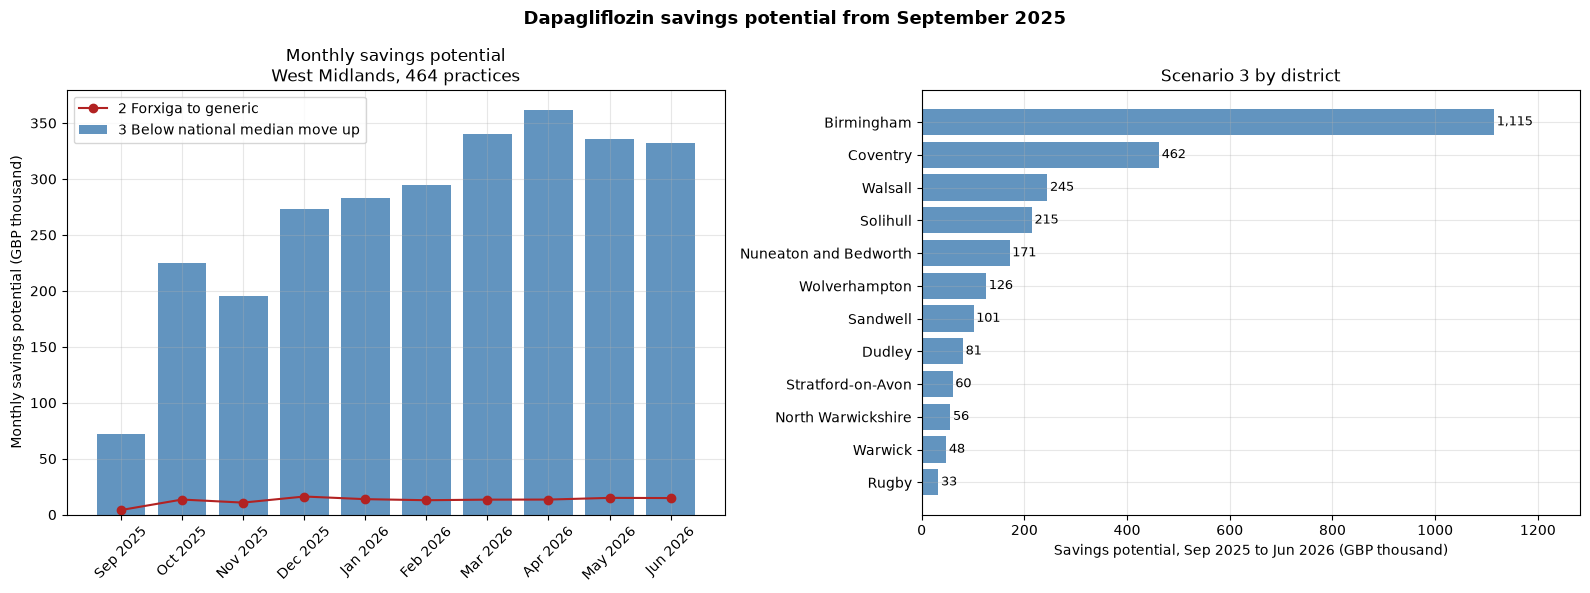

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].bar(monthly['date'].dt.strftime('%b %Y'), monthly['national_median'] / 1000,
            color='steelblue', alpha=0.85, label='3 Below national median move up')
axes[0].plot(monthly['date'].dt.strftime('%b %Y'), monthly['like_for_like'] / 1000,
             'o-', color='firebrick', label='2 Forxiga to generic')
axes[0].set_ylabel('Monthly savings potential (GBP thousand)')
axes[0].set_title('Monthly savings potential\nWest Midlands, 464 practices')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

d = district_savings.sort_values('national_median')
axes[1].barh(d['district'], d['national_median'] / 1000, color='steelblue', alpha=0.85)
axes[1].set_xlabel('Savings potential, Sep 2025 to Jun 2026 (GBP thousand)')
axes[1].set_title('Scenario 3 by district')
axes[1].grid(True, alpha=0.3)
for i, v in enumerate(d['national_median'] / 1000):
    axes[1].text(v + 5, i, f'{v:,.0f}', va='center', fontsize=9)
axes[1].set_xlim(0, (d['national_median'] / 1000).max() * 1.15)

plt.suptitle('Dapagliflozin savings potential from September 2025',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('epd_savings_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

**Step 14: Save results**

These replace the old files with the same names.

In [14]:
monthly.to_csv('monthly_savings.csv', index=False)
district_savings.to_csv('district_savings.csv', index=False)
icb_savings.to_csv('icb_savings.csv', index=False)
savings_summary.to_csv('savings_summary.csv', index=False)

print('Saved: monthly_savings.csv, district_savings.csv, icb_savings.csv,')
print('       savings_summary.csv, and the two charts')

Saved: monthly_savings.csv, district_savings.csv, icb_savings.csv,
       savings_summary.csv, and the two charts


**Acknowledgement of AI assistance**

This notebook was written by Mifta Mahmood with assistance from Claude (Anthropic), a generative AI assistant, which helped to write and debug the code. All code was run, checked and verified by the author, and the outputs shown are from the author's own runs. The final decisions on data, methods and interpretation are the author's own.